<a href="https://colab.research.google.com/github/sk6952217-pixel/Day10_Shivam-Kumar_Visual-EDA/blob/main/Day10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import zipfile # Import the zipfile module

zip_path = "/content/Underwater-Image-Data-set-main.zip" # Define the path to the ZIP file
extract_path = "/content/underwater_dataset" # Define the directory where the files will be extracted

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

In [16]:
# Install 7zip, a command-line archiving tool
!apt-get -qq install p7zip-full

# Define the path to the dataset folder which contains .7z archives
dataset = "/content/underwater_dataset/Underwater-Image-Data-set-main"

output = "/content/images"

!mkdir -p /content/images
!7z x "$dataset/*.7z" -o"$output" -y


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,2 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /content/underwater_dataset/Underwater-Image-Data-set-main/                                                                     8 files, 151077006 bytes (145 MiB)
  0%    
Extracting archive: /content/underwater_dataset/Underwater-Image-Data-set-main/epoch_00100.7z
--
Path = /content/underwater_dataset/Underwater-Image-Data-set-main/epoch_00100.7z
Type = 7z
Physical Size = 31290555
Headers Size = 8080
Method = LZMA:23
Solid = +
Blocks = 1

  0%      1%      3% 57 - epoch_0100/img 118_gen.png                                    

In [17]:
import os
import numpy as np
from PIL import Image

dataset = "/content/images"

input_count = 0 # Initialize a counter for input images
target_count = 0 # Initialize a counter for target images
gen_count = 0 # Initialize a counter for generated images

widths = [] # List to store image widths
heights = [] # List to store image heights
brightness = [] # List to store image brightness values

# Walk through all directories and files in the dataset folder
for root, dirs, files in os.walk(dataset):
    for file in files:
        if not file.endswith(".png"): # Skip any files that are not PNG images
            continue

        path = os.path.join(root, file)

        try:
            # Open the image and convert it to RGB format
            img = Image.open(path).convert("RGB")
            arr = np.array(img)

            widths.append(img.width) # Add the image width to the list
            heights.append(img.height) # Add the image height to the list
            brightness.append(arr.mean()) # Calculate and add the average brightness (mean pixel value) to the list

            if "_input.png" in file: # Check if the file name indicates an input image
                input_count += 1 # Increment the input image counter
            elif "_target.png" in file: # Check if the file name indicates a target image
                target_count += 1 # Increment the target image counter
            elif "_gen.png" in file: # Check if the file name indicates a generated image
                gen_count += 1 # Increment the generated image counter

        except:
            pass # For corrupted images

print("Input images:", input_count)
print("Target images:", target_count)
print("Generated images:", gen_count)

print("\nImage size:")
# Print the minimum and maximum observed widths of the images
print("Width:", min(widths), "to", max(widths))
# Print the minimum and maximum observed heights of the images
print("Height:", min(heights), "to", max(heights))

print("\nAverage brightness:", round(np.mean(brightness), 2)) # Print the average brightness
print("Minimum brightness:", round(np.min(brightness), 2)) # Print the minimum brightness
print("Maximum brightness:", round(np.max(brightness), 2)) # Print the maximum brightness

Input images: 1078
Target images: 1078
Generated images: 1078

Image size:
Width: 256 to 256
Height: 256 to 256

Average brightness: 108.42
Minimum brightness: 0.97
Maximum brightness: 252.12


In [18]:
# Initialize an empty dictionary to store image pairs
pairs = {}

# Walk through all directories and files in the dataset folder
for root, dirs, files in os.walk(dataset):
    for file in files:
        if file.endswith(".png"): # Process only PNG image files

            if "_input.png" in file: # If the file is an input image
                # Extract a common key from the filename
                key = file.replace("_input.png", "")
                # Add the input image path to the 'pairs' dictionary
                pairs.setdefault(key, {})["input"] = os.path.join(root, file)

            elif "_target.png" in file: # If the file is a target image
                # Extract a common key from the filename
                key = file.replace("_target.png", "")
                # Add the target image path to the 'pairs' dictionary
                pairs.setdefault(key, {})["target"] = os.path.join(root, file)

            elif "_gen.png" in file: # If the file is a generated image
                # Extract a common key from the filename
                key = file.replace("_gen.png", "")
                # Add the generated image path to the 'pairs' dictionary
                pairs.setdefault(key, {})["generated"] = os.path.join(root, file)

Complete pairs found: 312


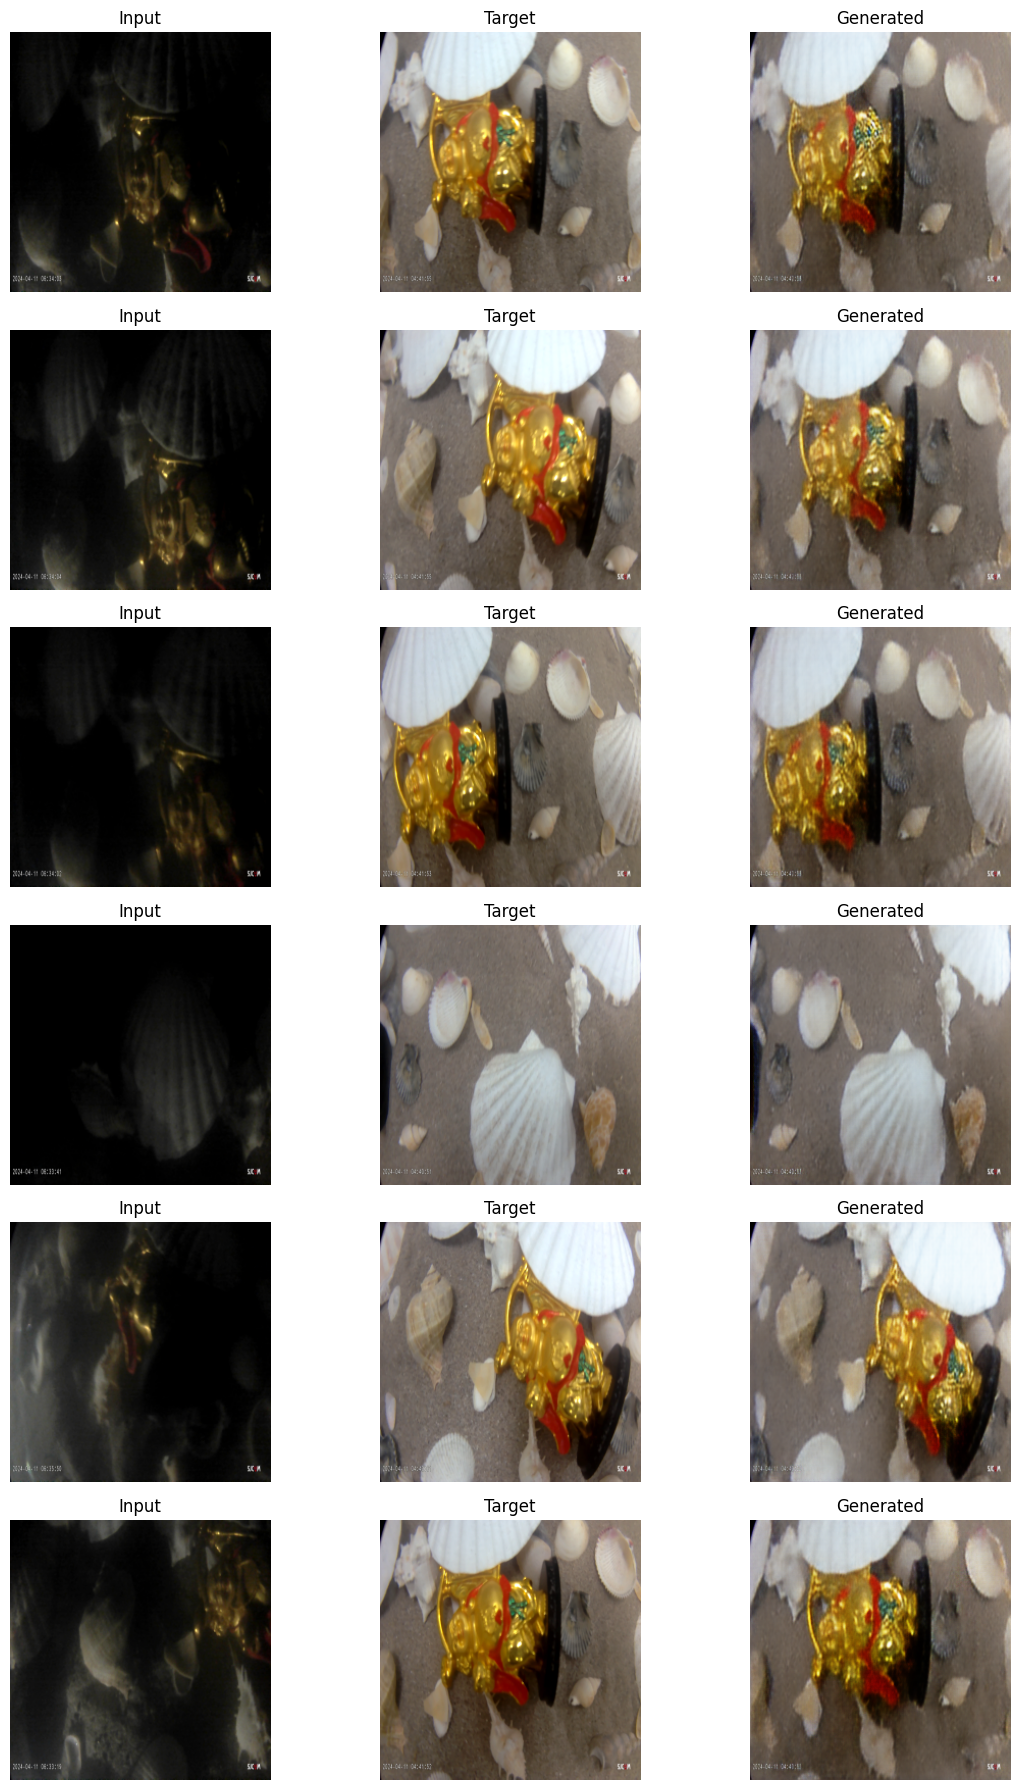

In [19]:
import matplotlib.pyplot as plt
# Filter the 'pairs' dictionary to keep only entries where 'input', 'target', and 'generated' images are all present
complete_pairs = [
    p for p in pairs.values()
    if "input" in p and "target" in p and "generated" in p # Check if all three keys exist in the current dictionary
]

print("Complete pairs found:", len(complete_pairs))

# Determine how many pairs to display (up to a maximum of 6)
n = min(6, len(complete_pairs))

plt.figure(figsize=(12, 3 * n))

for i in range(n):
    p = complete_pairs[i]

    plt.subplot(n, 3, i * 3 + 1)
    plt.imshow(Image.open(p["input"]))
    plt.title("Input")
    plt.axis("off")

    plt.subplot(n, 3, i * 3 + 2)
    plt.imshow(Image.open(p["target"]))
    plt.title("Target")
    plt.axis("off")

    plt.subplot(n, 3, i * 3 + 3)
    plt.imshow(Image.open(p["generated"]))
    plt.title("Generated")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
# Initialize empty lists to store brightness and contrast values of input images
brightness = []
contrast = []

# Walk through all directories and files in the dataset folder
for root, dirs, files in os.walk(dataset):
    for file in files:

        if "_input.png" in file: # Check if the file is an input image
            path = os.path.join(root, file) # Construct the full path to the image

            try:
                img = Image.open(path).convert("L")
                arr = np.array(img)

                brightness.append(arr.mean()) # Calculate and append the mean pixel value (brightness)
                contrast.append(arr.std()) # Calculate and append the standard deviation of pixel values (contrast)

            except:
                pass # If an error occurs

print("Number of input images:", len(brightness))

print("\nBrightness")
print("Average:", round(np.mean(brightness), 2))
print("Minimum:", round(np.min(brightness), 2))
print("Maximum:", round(np.max(brightness), 2))

print("\nContrast")
print("Average:", round(np.mean(contrast), 2))
print("Minimum:", round(np.min(contrast), 2))
print("Maximum:", round(np.max(contrast), 2))

Number of input images: 1078

Brightness
Average: 70.16
Minimum: 1.03
Maximum: 246.69

Contrast
Average: 26.68
Minimum: 2.19
Maximum: 73.32


In [21]:
# Initialize an empty list to store brightness and path for darkest images
darkest = []

# Walk through all directories and files in the dataset folder
for root, dirs, files in os.walk(dataset):
    for file in files:

        if "_input.png" in file: # Check if the file is an input image
            path = os.path.join(root, file) # Construct the full path to the image

            try:
                img = Image.open(path).convert("L")
                arr = np.array(img)

                # Append a tuple of (mean brightness, image path) to the list
                darkest.append((arr.mean(), path))

            except:
                pass # If an error occurs

darkest.sort() # Sort the list based on brightness

print("5 darkest input images:\n")

# Iterate through the first 5 elements
for value, path in darkest[:5]:
    print(round(value, 2), "→", path)

5 darkest input images:

1.03 → /content/images/epoch_0110/img 58_input.png
2.69 → /content/images/epoch_0110/img 140_input.png
3.65 → /content/images/epoch_0110/img 57_input.png
4.07 → /content/images/epoch_0110/img 141_input.png
4.21 → /content/images/epoch_0110/img 59_input.png


In [22]:
# Initialize an empty list to store contrast and path for lowest contrast images
low_contrast = []

# Walk through all directories and files in the dataset folder
for root, dirs, files in os.walk(dataset):
    for file in files:

        if "_input.png" in file: # Check if the file is an input image
            path = os.path.join(root, file) # Construct the full path to the image

            try:
                img = Image.open(path).convert("L")
                arr = np.array(img)

                # Append a tuple of (standard deviation of pixels, image path) to the list
                low_contrast.append((arr.std(), path))

            except:
                pass # If an error occurs

low_contrast.sort() # Sort the list based on contrast

print("5 lowest-contrast input images:\n")

# Iterate through the first 5 elements
for value, path in low_contrast[:5]:
    print(round(value, 2), "→", path)

5 lowest-contrast input images:

2.19 → /content/images/epoch_0096/img_22_input.png
2.19 → /content/images/epoch_0096/img_25_input.png
2.25 → /content/images/epoch_0096/img_23_input.png
2.47 → /content/images/epoch_0096/img_24_input.png
3.06 → /content/images/epoch_0096/img_14_input.png


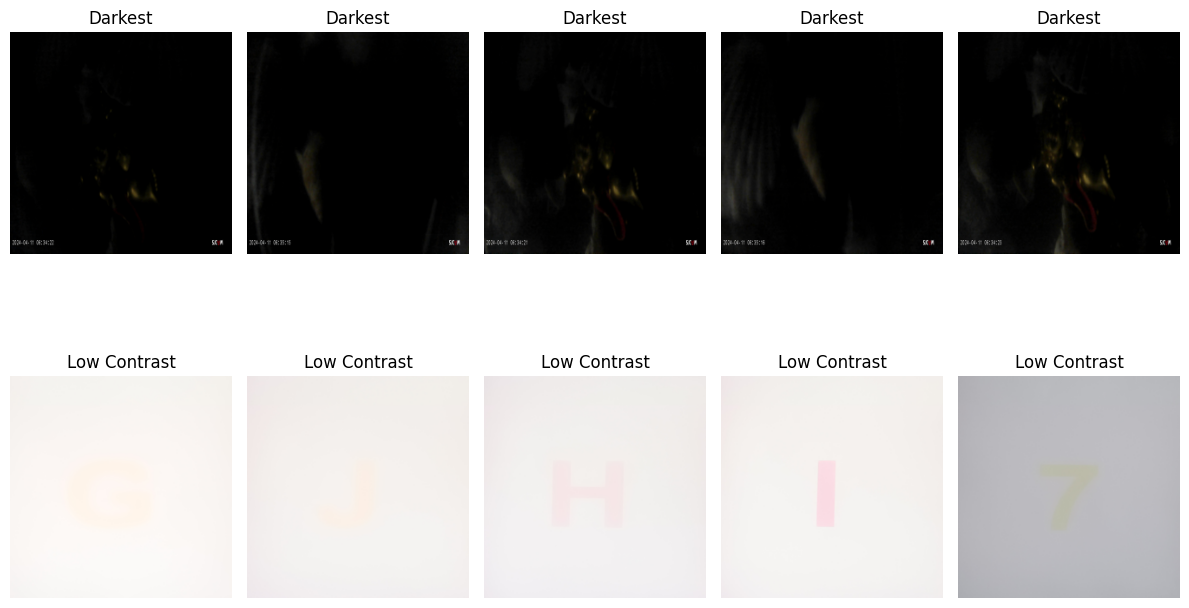

In [23]:
#Visualize the Darkest and Lowest-contrast image
import os
import matplotlib.pyplot as plt
from PIL import Image

darkest = [
    "/content/images/epoch_0110/img 58_input.png",
    "/content/images/epoch_0110/img 140_input.png",
    "/content/images/epoch_0110/img 57_input.png",
    "/content/images/epoch_0110/img 141_input.png",
    "/content/images/epoch_0110/img 59_input.png"
]

low_contrast = [
    "/content/images/epoch_0096/img_22_input.png",
    "/content/images/epoch_0096/img_25_input.png",
    "/content/images/epoch_0096/img_23_input.png",
    "/content/images/epoch_0096/img_24_input.png",
    "/content/images/epoch_0096/img_14_input.png"
]

plt.figure(figsize=(12, 8))

for i, path in enumerate(darkest):
    plt.subplot(2, 5, i + 1)
    plt.imshow(Image.open(path))
    plt.title("Dark")
    plt.axis("off")

for i, path in enumerate(low_contrast):
    plt.subplot(2, 5, i + 6)
    plt.imshow(Image.open(path))
    plt.title("Low Contrast")
    plt.axis("off")

plt.tight_layout()
plt.show()